# Pump Telemetry Presentation Workbook

## The Problem: A Pump You Can't Afford to Lose

A high-pressure water-injection pump feeds a reverse-osmosis desalination plant. Two failure modes threaten it: **cavitation** (vapour bubbles collapsing inside the impeller when intake pressure sags) and **bearing seizure** (accumulated mechanical wear ending in sudden failure). Either one takes the plant offline.

The pump streams telemetry once a minute — vibration, pressure, motor temperature. The question this workbook answers: **can we turn that noisy sensor stream into an early warning an engineer can trust?**

> **Analytics anchor:** this is a forecasting problem on messy operational data — the same kind of data you already analyse, one step closer to the sensor. Every ML idea in this notebook has a direct analogue in analytics work you already do, and each section names it.

## Helper Functions:

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shap

In [2]:
from scipy.signal import savgol_filter
from sklearn.ensemble import RandomForestRegressor
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import Matern, ConstantKernel
from sklearn.metrics import r2_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

project_root = Path.cwd()
hidden_dir = project_root / 'Hidden'
if str(hidden_dir) not in sys.path:
    sys.path.insert(0, str(hidden_dir))

from presentation_emulator import PumpTelemetryEmulator

In [3]:
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams.update({
    'figure.figsize': (12, 6),
    'figure.dpi': 120,
    'axes.titlesize': 13,
    'axes.titleweight': 'bold',
    'axes.labelsize': 11,
    'legend.frameon': False,
    'font.size': 10,
    'grid.alpha': 0.25,
})

raw_features = ['raw_vibration']
engineered_features = ['vibration_rms', 'vibration_trend', 'pressure_reserve', 'motor_temp']
csv_path = project_root / 'presentation_pump_telemetry.csv'

# Regime boundary hours — used throughout for consistent plot annotations
NOMINAL_END_H   = 320.0
FAILURE_START_H = 360.0
TRAIN_CUTOFF_H  = 380.0
SEIZURE_H       = 490.0

def add_regime_lines(ax, legend=True):
    """Add consistent nominal/failure/train-cutoff vertical markers to a time-axis plot."""
    ax.axvline(x=NOMINAL_END_H,   color='#e69f00', linestyle=':', linewidth=1.4, label='Nominal end (320 h)')
    ax.axvline(x=FAILURE_START_H, color='#cc3311', linestyle=':', linewidth=1.4, label='Failure onset (360 h)')
    ax.axvline(x=TRAIN_CUTOFF_H,  color='#444444', linestyle='-.', linewidth=1.2, label='Train cutoff (380 h)')
    if legend:
        ax.legend(loc='upper left')

def rolling_rms(signal, window=61):
    series = pd.Series(signal, dtype='float64')
    return series.rolling(window=window, min_periods=1, center=True).apply(lambda arr: float(np.sqrt(np.mean(np.square(arr)))), raw=True).bfill().ffill().to_numpy()

def rolling_trend(signal, window=31):
    values = np.asarray(signal, dtype=float)
    half_window = window // 2
    trend_values = []
    for index in range(values.size):
        start = max(0, index - half_window)
        stop = min(values.size, index + half_window + 1)
        window_values = values[start:stop]
        if window_values.size < 2:
            trend_values.append(np.nan)
        else:
            trend_values.append((window_values[-1] - window_values[0]) / max(1, window_values.size - 1))
    return pd.Series(trend_values).bfill().ffill().to_numpy()

def enforce_physical_limits(predictions, inputs):
    """Clip predictions to [0, 1] and apply domain rule: severe pressure deficit caps efficiency at 0.35."""
    bounded = np.clip(np.asarray(predictions, dtype=float), 0.0, 1.0)
    cavitation_mask = inputs['pressure_reserve'].to_numpy() < -8.0
    bounded = np.where(cavitation_mask, np.minimum(bounded, 0.35), bounded)
    return bounded

## Emulator Generation

This emulator recreates the sensor data a real pump monitoring system would produce — including measurement noise, electrical interference, random transient bursts, sensor dropouts, and a slowly developing bearing fault that eventually drives the pump into a failure regime ending in a bearing seizure at hour 490.

The generated CSV contains only the **raw sensor readings** and the efficiency target. The engineered features (`calibrated_pressure`, `pressure_reserve`, `vibration_rms`, `vibration_trend`) are deliberately withheld from the file so that deriving them is a meaningful step in this notebook.

## Data Schema

Columns present in the raw CSV file:

| Column | Meaning | Unit |
|---|---|---|
| `timestamp` | Absolute sample time | ISO datetime |
| `time_hours` | Time since start of run | hours |
| `raw_vibration` | Noisy vibration sensor reading | relative amplitude (a.u.) |
| `drifted_pressure` | Measured pressure with sensor drift | kPa |
| `motor_temp` | Motor casing temperature | °C |
| `fluid_temp` | Process fluid temperature | °C |
| `pump_efficiency` | Target variable for the model | unitless |
| `suggested_split` | `"train"` (0–380 h) or `"test"` (380–500 h) | — |

Columns derived in this notebook (the feature engineering step):

| Column | How derived | Why |
|---|---|---|
| `calibrated_pressure` | `drifted_pressure` − drift correction | Removes known sensor offset |
| `pressure_reserve` | `calibrated_pressure` − rolling mean | Detects drops relative to local baseline |
| `vibration_rms` | Rolling RMS of cleaned vibration | Captures energy envelope of the signal |
| `vibration_trend` | Rolling slope of cleaned vibration | Detects whether vibration is rising or falling |

In [4]:
emulator = PumpTelemetryEmulator()
telemetry_df = emulator.generate(csv_path)
print(f"Generated {len(telemetry_df)} records; sensor-dropout frames: {telemetry_df.attrs['dropout_count']}")
telemetry_df[['timestamp', 'time_hours', 'raw_vibration', 'drifted_pressure', 'motor_temp', 'pump_efficiency']].head()

Generated 30000 records; sensor-dropout frames: 635


,timestamp,time_hours,raw_vibration,drifted_pressure,motor_temp,pump_efficiency
0,2026-01-01 00:00:00.000000000,0.000000,-0.251454,120.716800,59.999198,0.925920
1,2026-01-01 00:01:00.000000001,0.016667,0.455016,121.038914,58.916705,0.927575
2,2026-01-01 00:01:59.999999998,0.033333,0.689745,120.727313,58.433402,0.953874
3,2026-01-01 00:03:00.000000000,0.050000,0.750176,120.955960,59.434545,0.906734
4,2026-01-01 00:04:00.000000001,0.066667,0.634791,121.139628,61.261852,0.941143


## Cleaning the Telemetry

> **Physical situation:** Every sensor on this pump is imperfect. The vibration transducer picks up electrical interference from nearby motors. The pressure transducer's output drifts as it warms up over a shift. And communication dropouts mean some windows of readings simply never arrive. Before any ML can start, these artefacts need to be removed using knowledge of *how the sensor works* — not learned from data.

**Analytics anchor:** this is the same discipline as fixing nulls, duplicates and unit errors before you build a pivot — except the correction rules come from knowing the sensor, not from eyeballing the data.

Three things go wrong with raw sensor data before we can learn from it:

1. **Sensor dropouts** — windows of readings go `NaN` due to communication faults. Forward-filling restores continuity without inventing new values.
2. **High-frequency noise** — the raw vibration signal is dominated by electrical hash and mechanical carrier frequencies. A Savitzky-Golay filter smooths the noise floor while preserving the structural peaks that indicate bearing state.
3. **Sensor drift** — the pressure transducer drifts at a known rate (-0.065 kPa/h). Subtracting the drift deterministically unlocks the pressure signal for use in the model.

These three steps are *engineering knowledge applied to data*, not statistics. The model cannot learn them from data alone — they require knowing how the sensor works.

---

**What to notice in the plots:** the vibration cleaning separates genuine structural bursts from the carrier noise; the pressure correction removes the downward slope, leaving a stable baseline the model can reason about; the dropout panel shows NaN gaps in the raw stream that forward-fill closes without inventing new values.

In [5]:
working_df = telemetry_df.copy()
sensor_columns = ['raw_vibration', 'drifted_pressure', 'motor_temp', 'fluid_temp']
working_df[sensor_columns] = working_df[sensor_columns].ffill().bfill()
working_df['cleaned_vibration'] = savgol_filter(working_df['raw_vibration'].to_numpy(), window_length=15, polyorder=2)
working_df['calibrated_pressure'] = working_df['drifted_pressure'].to_numpy() - (-0.065 * working_df['time_hours'].to_numpy())
working_df['vibration_rms'] = rolling_rms(working_df['cleaned_vibration'].to_numpy(), window=61)
working_df['vibration_trend'] = rolling_trend(working_df['cleaned_vibration'].to_numpy(), window=31)
working_df['pressure_reserve'] = working_df['calibrated_pressure'].to_numpy() - pd.Series(working_df['calibrated_pressure']).rolling(window=91, min_periods=1, center=True).mean().bfill().ffill().to_numpy()

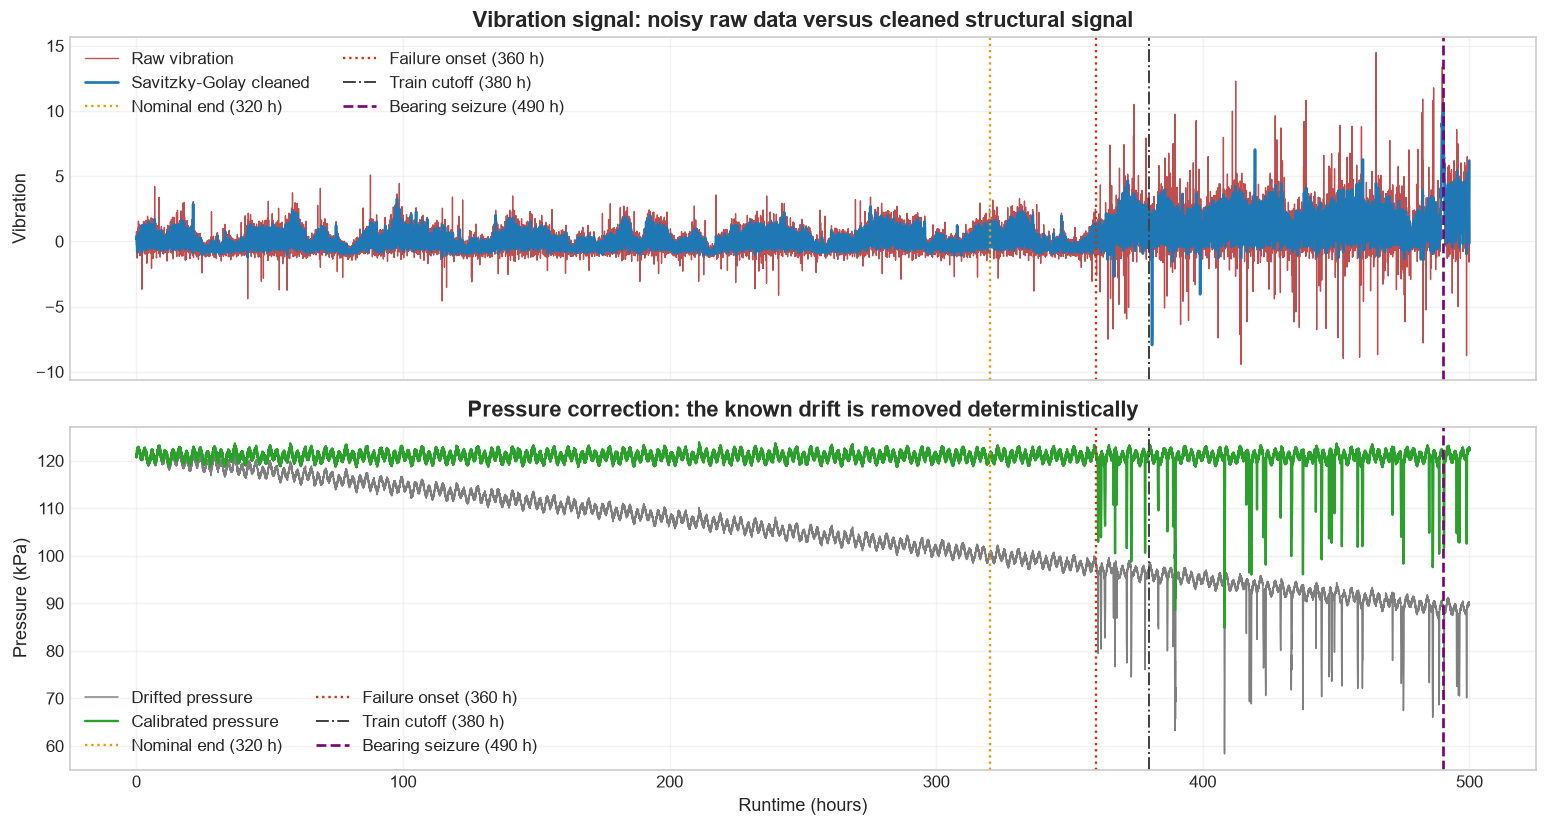

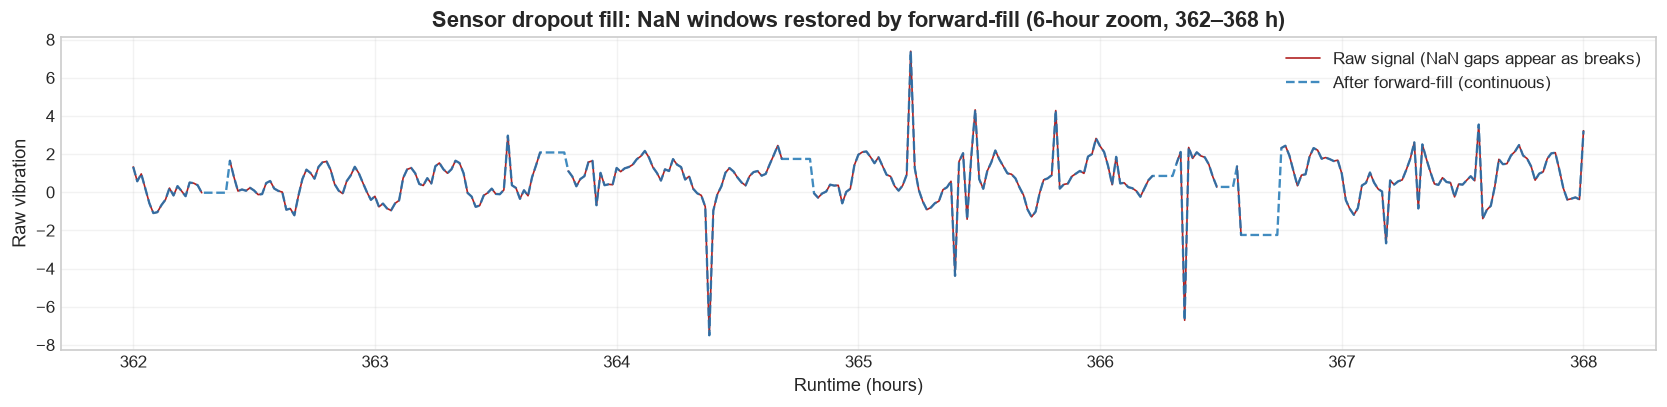

In [6]:
fig, axes = plt.subplots(2, 1, figsize=(13, 7), sharex=True)
axes[0].plot(working_df['time_hours'], working_df['raw_vibration'], color='#b22222', linewidth=0.8, alpha=0.8, label='Raw vibration')
axes[0].plot(working_df['time_hours'], working_df['cleaned_vibration'], color='#1f77b4', linewidth=1.6, label='Savitzky-Golay cleaned')
axes[0].set_title('Vibration signal: noisy raw data versus cleaned structural signal')
axes[0].set_ylabel('Vibration')

axes[1].plot(working_df['time_hours'], working_df['drifted_pressure'], color='#7f7f7f', linewidth=0.9, label='Drifted pressure')
axes[1].plot(working_df['time_hours'], working_df['calibrated_pressure'], color='#2ca02c', linewidth=1.4, label='Calibrated pressure')
axes[1].set_title('Pressure correction: the known drift is removed deterministically')
axes[1].set_xlabel('Runtime (hours)')
axes[1].set_ylabel('Pressure (kPa)')

for ax in axes:
    add_regime_lines(ax, legend=False)
    ax.axvline(x=SEIZURE_H, color='#7a0177', linestyle='--', linewidth=1.6, label=f'Bearing seizure ({SEIZURE_H:.0f} h)')
axes[0].legend(loc='upper left', ncols=2)
axes[1].legend(loc='lower left', ncols=2)
plt.tight_layout()
plt.show()

# Dropout zoom: NaN gaps in the raw stream, closed by forward-fill
dropout_zoom_mask = (working_df['time_hours'] >= 362) & (working_df['time_hours'] <= 368)
fig2, ax2 = plt.subplots(figsize=(14, 3.5))
ax2.plot(telemetry_df.loc[dropout_zoom_mask, 'time_hours'],
         telemetry_df.loc[dropout_zoom_mask, 'raw_vibration'],
         color='#b22222', linewidth=1.0, label='Raw signal (NaN gaps appear as breaks)')
ax2.plot(working_df.loc[dropout_zoom_mask, 'time_hours'],
         working_df.loc[dropout_zoom_mask, 'raw_vibration'],
         color='#1f77b4', linewidth=1.4, linestyle='--', alpha=0.85, label='After forward-fill (continuous)')
ax2.set_title('Sensor dropout fill: NaN windows restored by forward-fill (6-hour zoom, 362–368 h)')
ax2.set_xlabel('Runtime (hours)')
ax2.set_ylabel('Raw vibration')
ax2.legend(loc='upper right')
plt.tight_layout()
plt.show()

## Raw Signal, Frequency Decomposition, and Engineered Features

> **Physical situation:** From failure onset (~360 h) the bearing races are accumulating micro-damage — surface fatigue from repeated contact stress. This shows up as low-frequency load oscillations and a rising energy envelope in the vibration signal. A single sensor reading at any moment is dominated by noise. But the *statistical envelope of the signal over time* tells a clear story.

**Analytics anchor:** engineered features are calculated columns — rolling measures over a time window, exactly like a 12-week moving average in a sales dashboard. Nothing here is exotic; it is aggregation with a purpose.

The raw vibration signal is almost entirely noise in the time domain — the machine state is hidden inside it.

The FFT reveals the contrast: a healthy pump (100-124 h) has a characteristic carrier spectrum; a degraded pump (400-424 h) carries more energy across the band as the bearing damage modulates the carrier in multiple ways. But even FFT magnitudes are noisy per-sample quantities that fluctuate wildly from minute to minute.

The engineered features turn those signatures into slow, stable state variables:
- `vibration_rms` — the overall energy envelope of the vibration signal
- `vibration_trend` — whether that energy is rising or falling
- `pressure_reserve` — how far the operating pressure has deviated from the local rolling baseline
- `motor_temp` — accumulated thermal load on the motor casing

These are the quantities a domain expert would compute by hand given a strip chart. They describe the *physical state* of the machine, not a snapshot of a single sensor reading.

---

**What to notice:** the engineered features track the machine's state throughout — they vary with load even in the healthy regime, then deviate sharply from failure onset (360 h), giving 130 hours of warning before the bearing seizure at 490 h. The raw data hides that warning completely.

In [7]:
# FFT: compare a nominal window (healthy) vs a failure-regime window (degraded)
dt_hours = float(working_df['time_hours'].iloc[1] - working_df['time_hours'].iloc[0])

nominal_win = working_df[(working_df['time_hours'] >= 100) & (working_df['time_hours'] <= 124)].copy()
failure_win = working_df[(working_df['time_hours'] >= 400) & (working_df['time_hours'] <= 424)].copy()

def compute_fft(df_win, col):
    sig = df_win[col].to_numpy()
    return np.abs(np.fft.rfft(sig - sig.mean()))

freq_nom  = np.fft.rfftfreq(len(nominal_win),  d=dt_hours)
freq_fail = np.fft.rfftfreq(len(failure_win), d=dt_hours)
nom_fft   = compute_fft(nominal_win,  'cleaned_vibration')
fail_fft  = compute_fft(failure_win, 'cleaned_vibration')
# Exclude the DC bin: after mean subtraction it is a ~1e-14 residual that
# would otherwise stretch the log axis to nothing
fft_mask_nom  = (freq_nom > 0) & (freq_nom <= 6.0)
fft_mask_fail = (freq_fail > 0) & (freq_fail <= 6.0)

# Time-domain reference window — show full nominal period for context
window_df = working_df[(working_df['time_hours'] >= 50) & (working_df['time_hours'] < NOMINAL_END_H)].copy()

feature_frame = working_df[['vibration_rms', 'vibration_trend', 'pressure_reserve', 'motor_temp']].copy()
feature_z = (feature_frame - feature_frame.mean()) / feature_frame.std(ddof=0)
train_mask = working_df['suggested_split'] == 'train'
train_start = working_df.loc[train_mask, 'time_hours'].min()
train_end = working_df.loc[train_mask, 'time_hours'].max()

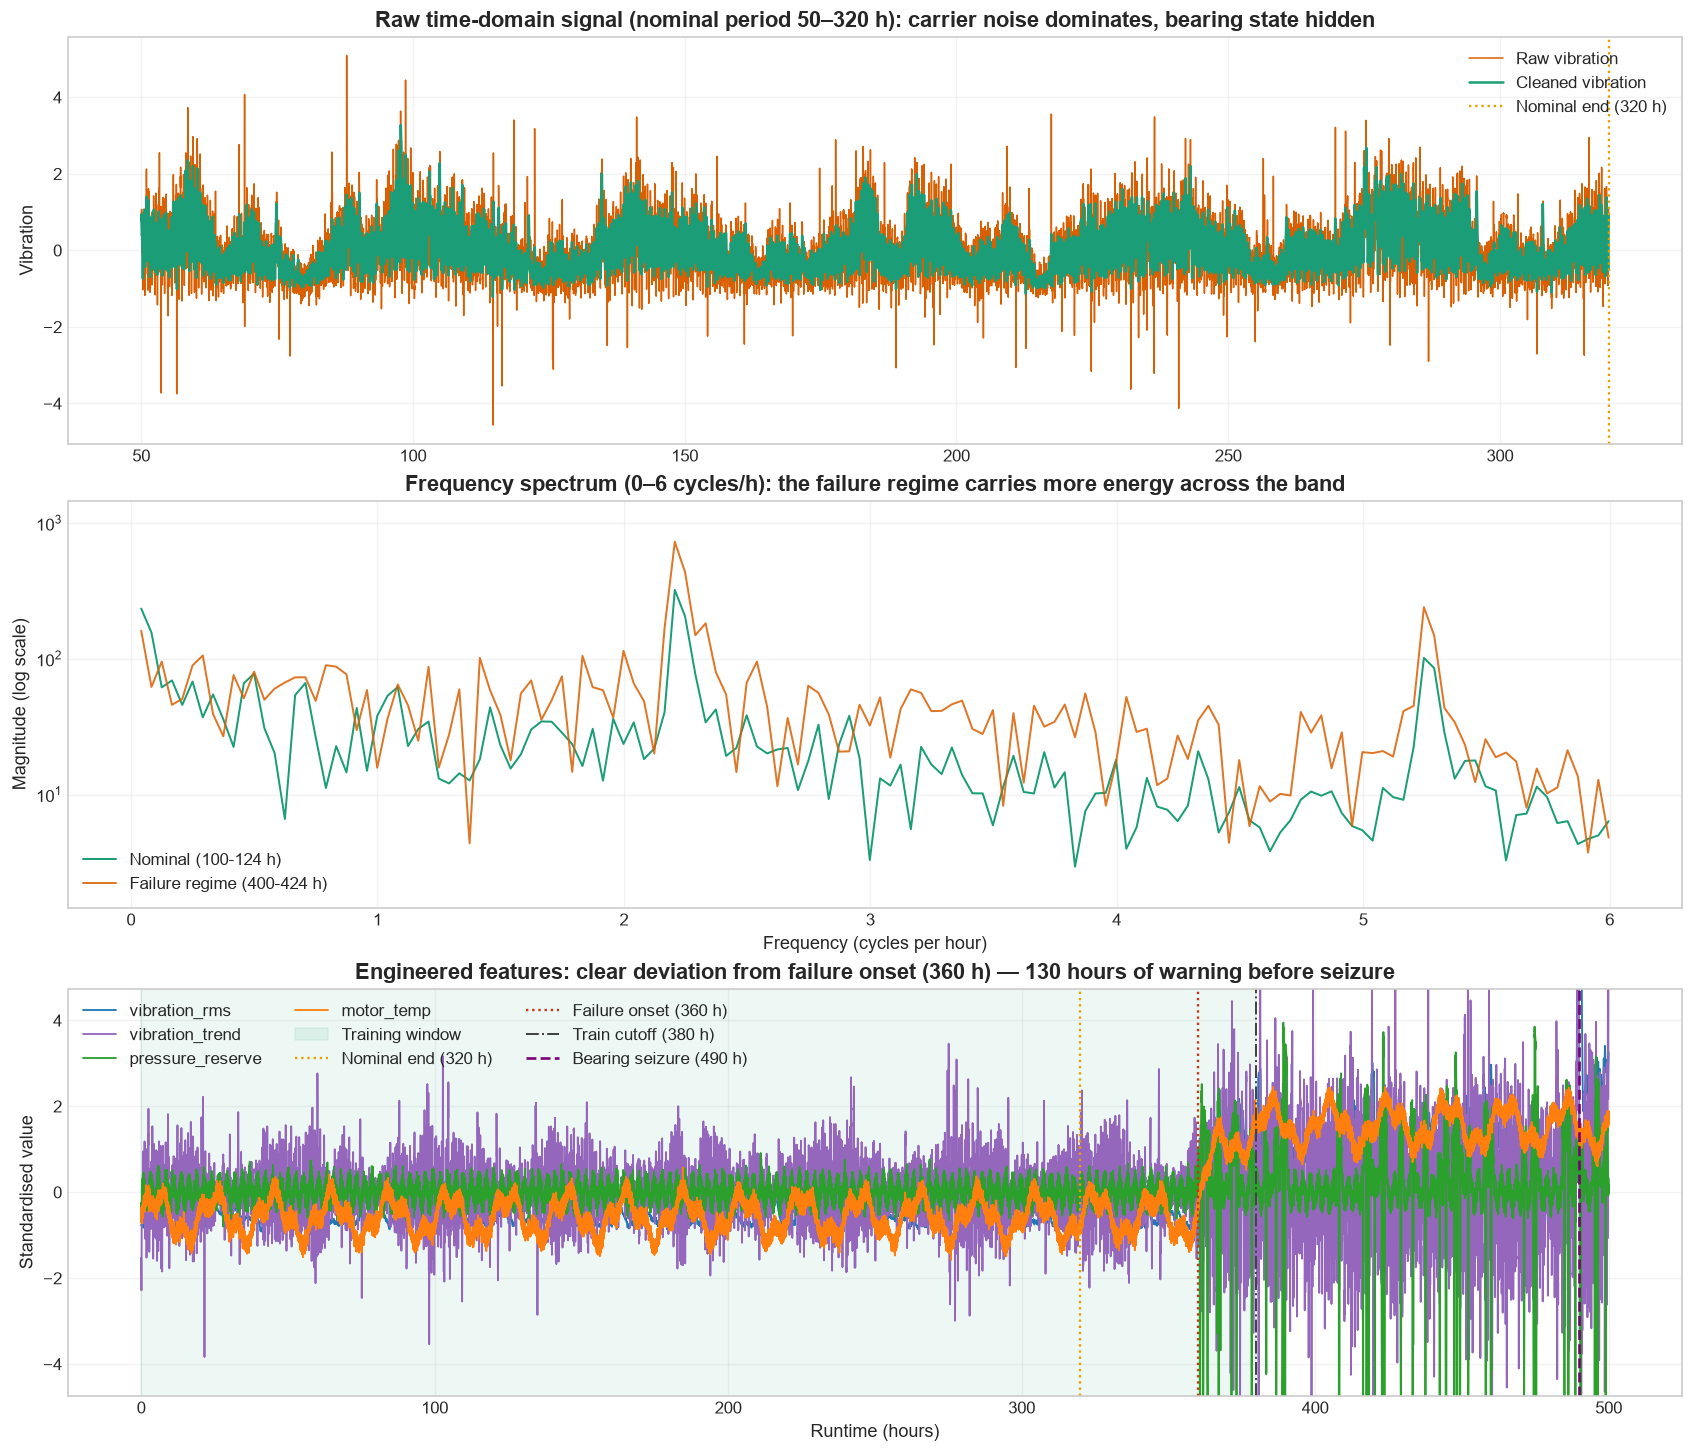

In [8]:
fig, axes = plt.subplots(3, 1, figsize=(14, 12), constrained_layout=True)

axes[0].plot(window_df['time_hours'], window_df['raw_vibration'], color='#d95f02', linewidth=0.9, label='Raw vibration')
axes[0].plot(window_df['time_hours'], window_df['cleaned_vibration'], color='#1b9e77', linewidth=1.5, label='Cleaned vibration')
axes[0].axvline(x=NOMINAL_END_H, color='#e69f00', linestyle=':', linewidth=1.4, label='Nominal end (320 h)')
axes[0].set_title('Raw time-domain signal (nominal period 50–320 h): carrier noise dominates, bearing state hidden')
axes[0].set_ylabel('Vibration')
axes[0].legend(loc='upper right')

axes[1].semilogy(freq_nom[fft_mask_nom],   nom_fft[fft_mask_nom],   color='#1b9e77', linewidth=1.2, label='Nominal (100-124 h)')
axes[1].semilogy(freq_fail[fft_mask_fail], fail_fft[fft_mask_fail], color='#d95f02', linewidth=1.2, label='Failure regime (400-424 h)', alpha=0.85)
axes[1].set_title('Frequency spectrum (0–6 cycles/h): the failure regime carries more energy across the band')
axes[1].set_xlabel('Frequency (cycles per hour)')
axes[1].set_ylabel('Magnitude (log scale)')
axes[1].legend(loc='lower left')
_all_fft = np.concatenate([nom_fft[fft_mask_nom], fail_fft[fft_mask_fail]])
axes[1].set_ylim(_all_fft.min() * 0.5, _all_fft.max() * 2.0)

for feature_name, color in zip(engineered_features, ['#1f77b4', '#9467bd', '#2ca02c', '#ff7f0e']):
    axes[2].plot(working_df['time_hours'], feature_z[feature_name], linewidth=1.1, color=color, label=feature_name)
axes[2].axvspan(train_start, train_end, color='#1b9e77', alpha=0.08, label='Training window')
add_regime_lines(axes[2], legend=False)
axes[2].axvline(x=SEIZURE_H, color='#7a0177', linestyle='--', linewidth=1.6, label=f'Bearing seizure ({SEIZURE_H:.0f} h)')
y_cap = float(np.percentile(np.abs(feature_z.to_numpy()), 99.5))
axes[2].set_ylim(-y_cap, y_cap)
axes[2].legend(loc='upper left', ncols=3)
axes[2].set_title('Engineered features: clear deviation from failure onset (360 h) — 130 hours of warning before seizure')
axes[2].set_xlabel('Runtime (hours)')
axes[2].set_ylabel('Standardised value')

plt.show()

## Raw Features versus Engineered Features — and the Split Trap

> **Physical situation:** We now have two modelling choices to compare: train on the raw vibration reading (one noisy number per timestep), or on the four engineered state variables (which encode the physical degradation trajectory). We also have two evaluation choices: split randomly (as most tutorials show) or split chronologically (as deployment actually demands — the model will always be asked to predict the *future*, not a shuffled mix of past and future).

**Analytics anchor:** a shuffled evaluation asks the model to "predict" a random mix of readings it has effectively already seen — like validating a sales forecast against last year. The chronological split asks it to forecast next quarter. Only one of those matches how the model will be used.

Two Random Forest models are trained on identical data with identical algorithm settings. The only difference is which columns they receive: **one raw scalar sensor reading** versus **four physics-aware state variables**.

But there is a second story hidden in this section: **how you split the data changes what the score means**.

We show both splits side by side:
- **Shuffled split** — the standard tutorial approach. Future failure readings contaminate the training set. Scores look better than the model deserves.
- **Chronological split** — train on the past (0-380 h), test on the future (380-500 h). This is what deployment actually demands.

---

**What to notice:** Feature engineering dominates in both cases. But the chronological split shows you how much — and exposes how little the raw-feature model can actually do when asked to predict a regime it has never encountered.

In [9]:
model_df = working_df.dropna(subset=['pump_efficiency']).copy()

# ── Shuffled split ─── the way most tutorials show it (and why it misleads) ──────
train_shuf, test_shuf = train_test_split(model_df, test_size=0.3, random_state=42, shuffle=True)

rf_raw_shuf = RandomForestRegressor(n_estimators=120, random_state=42, n_jobs=-1)
rf_raw_shuf.fit(train_shuf[raw_features], train_shuf['pump_efficiency'])
r2_raw_shuf = r2_score(test_shuf['pump_efficiency'], rf_raw_shuf.predict(test_shuf[raw_features]))

rf_eng_shuf = RandomForestRegressor(n_estimators=160, random_state=42, n_jobs=-1)
rf_eng_shuf.fit(train_shuf[engineered_features], train_shuf['pump_efficiency'])
r2_eng_shuf = r2_score(test_shuf['pump_efficiency'], rf_eng_shuf.predict(test_shuf[engineered_features]))

# ── Chronological split ── train on past, test on future (deployment reality) ────
train_df = model_df[model_df['suggested_split'] == 'train'].copy()
test_df  = model_df[model_df['suggested_split'] == 'test'].copy()

baseline_model = RandomForestRegressor(n_estimators=120, random_state=42, n_jobs=-1)
baseline_model.fit(train_df[raw_features], train_df['pump_efficiency'])
baseline_predictions = baseline_model.predict(test_df[raw_features])
baseline_r2 = r2_score(test_df['pump_efficiency'], baseline_predictions)

engineered_model = RandomForestRegressor(n_estimators=160, random_state=42, n_jobs=-1)
engineered_model.fit(train_df[engineered_features], train_df['pump_efficiency'])
engineered_predictions = engineered_model.predict(test_df[engineered_features])
engineered_r2 = r2_score(test_df['pump_efficiency'], engineered_predictions)

print("Shuffled split  (future failure rows leak into training):")
print(f"  Raw-feature R²:        {r2_raw_shuf:.3f}   ← looks like a weak but usable model")
print(f"  Engineered-feature R²: {r2_eng_shuf:.3f}   ← looks excellent")
print()
print("Chronological split  (train on past 0–380 h, test on future 380–500 h):")
print(f"  Raw-feature R²:        {baseline_r2:.3f}   ← collapses: far worse than predicting the mean")
print(f"  Engineered-feature R²: {engineered_r2:.3f}   ← survives, but the honest score is lower")

Shuffled split  (future failure rows leak into training):
  Raw-feature R²:        0.144   ← looks like a weak but usable model
  Engineered-feature R²: 0.963   ← looks excellent

Chronological split  (train on past 0–380 h, test on future 380–500 h):
  Raw-feature R²:        -6.125   ← collapses: far worse than predicting the mean
  Engineered-feature R²: 0.311   ← survives, but the honest score is lower


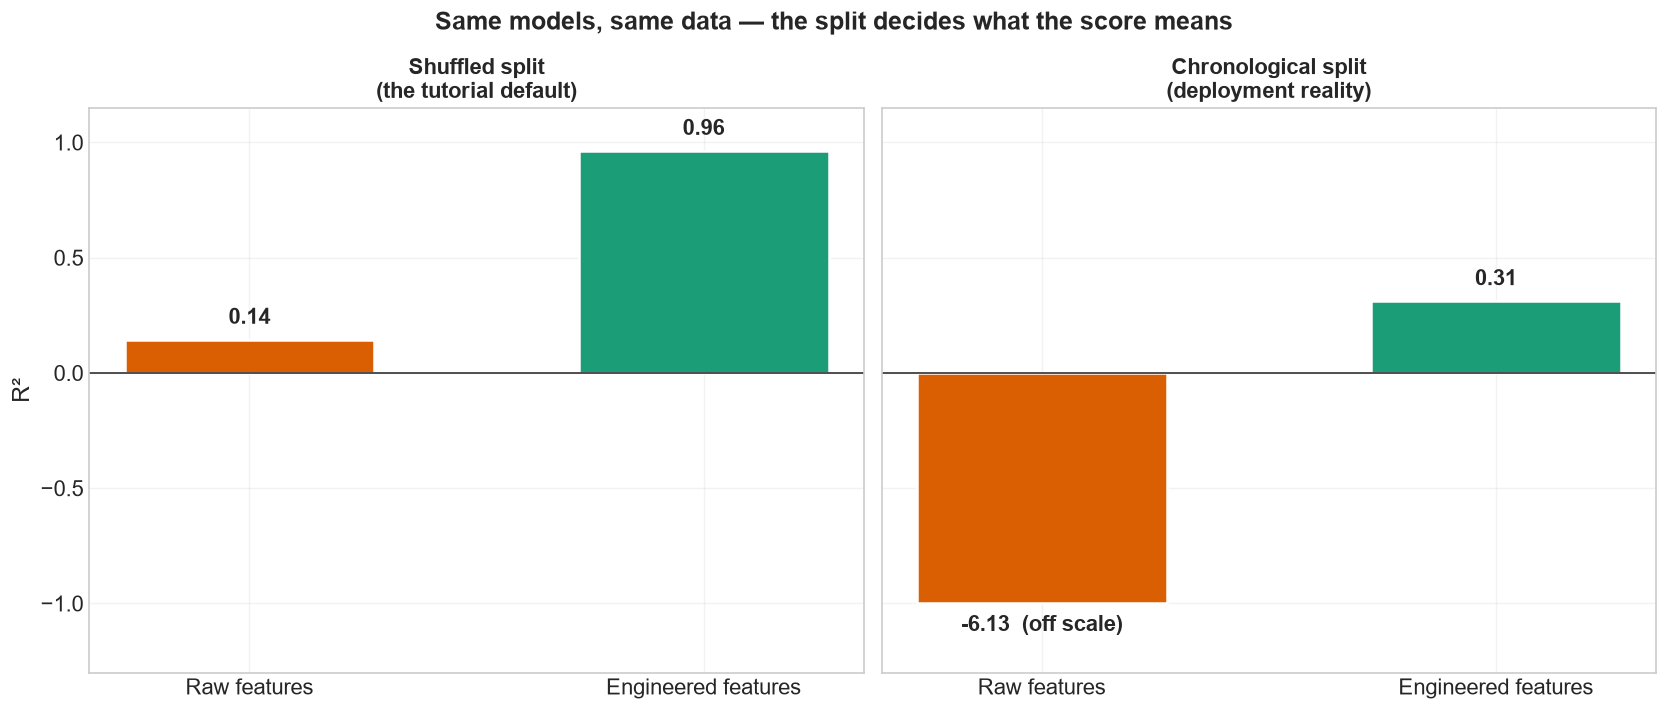

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6), sharey=True)
panels = [
    ('Shuffled split\n(the tutorial default)', [r2_raw_shuf, r2_eng_shuf]),
    ('Chronological split\n(deployment reality)', [baseline_r2, engineered_r2]),
]
for ax, (title, values) in zip(axes, panels):
    display = [max(v, -1.0) for v in values]
    bars = ax.bar(['Raw features', 'Engineered features'], display,
                  color=['#d95f02', '#1b9e77'], width=0.55, edgecolor='white', linewidth=1.5)
    ax.axhline(0, color='#444444', linewidth=1.1)
    ax.set_ylim(-1.3, 1.15)
    ax.set_title(title, fontsize=13)
    ax.tick_params(axis='both', labelsize=13)
    for bar, value in zip(bars, values):
        label = f'{value:.2f}' + ('  (off scale)' if value < -1.0 else '')
        if value >= 0:
            ypos, va = bar.get_height() + 0.05, 'bottom'
        else:
            ypos, va = bar.get_height() - 0.05, 'top'
        ax.text(bar.get_x() + bar.get_width() / 2, ypos, label,
                ha='center', va=va, fontsize=13, fontweight='bold')
axes[0].set_ylabel('R²', fontsize=14)
fig.suptitle('Same models, same data — the split decides what the score means',
             fontsize=15, weight='bold')
plt.tight_layout()
plt.show()

### The split trap — why the shuffled scores flatter the models

When rows are shuffled before splitting, future failure-regime readings end up in the training set. The model effectively memorises what failure looks like *before* being asked to predict it. The test set is no longer unseen — it is just more of the same distribution.

The chronological split removes that illusion. Training sees only hours 0–380; the test set is hours 380–500, the part of the lifespan the model has never encountered. Three things become clear:

- **Both scores drop** when the split is honest. The task is genuinely harder than the shuffled score suggests.
- **The raw-feature model collapses to a strongly negative R²** — worse than just predicting the average — once the machine leaves the operating regime it was trained on.
- **The engineered model survives** because the physical state features (`vibration_rms`, `pressure_reserve`, etc.) encode *why* the machine is degrading, not just *what* the last sensor reading was.

---

**Core argument:** not just better R², but R² that holds up when it matters. A metric that collapses the moment you evaluate honestly is not a metric at all.

## Prediction Diagnostics

These two plots show what the models actually produce, point by point, on the chronological test set (hours 380–500 — the future the models never saw during training).

The **left panel** maps predicted efficiency against actual. A perfect model would lie on the dashed diagonal. Notice how the raw-feature baseline is a cloud with little diagonal structure, while the engineered model clusters much closer to the ideal line.

The **right panel** shows the engineered model's residuals over time.

**What to notice on the right:** residuals are small and symmetric through the early test window. As the pump approaches and passes the bearing seizure at hour 490, the residuals grow and become structured — the model is extrapolating beyond what it was trained on, and the errors increase in magnitude. This is the warning signal a monitoring system would need to act on.

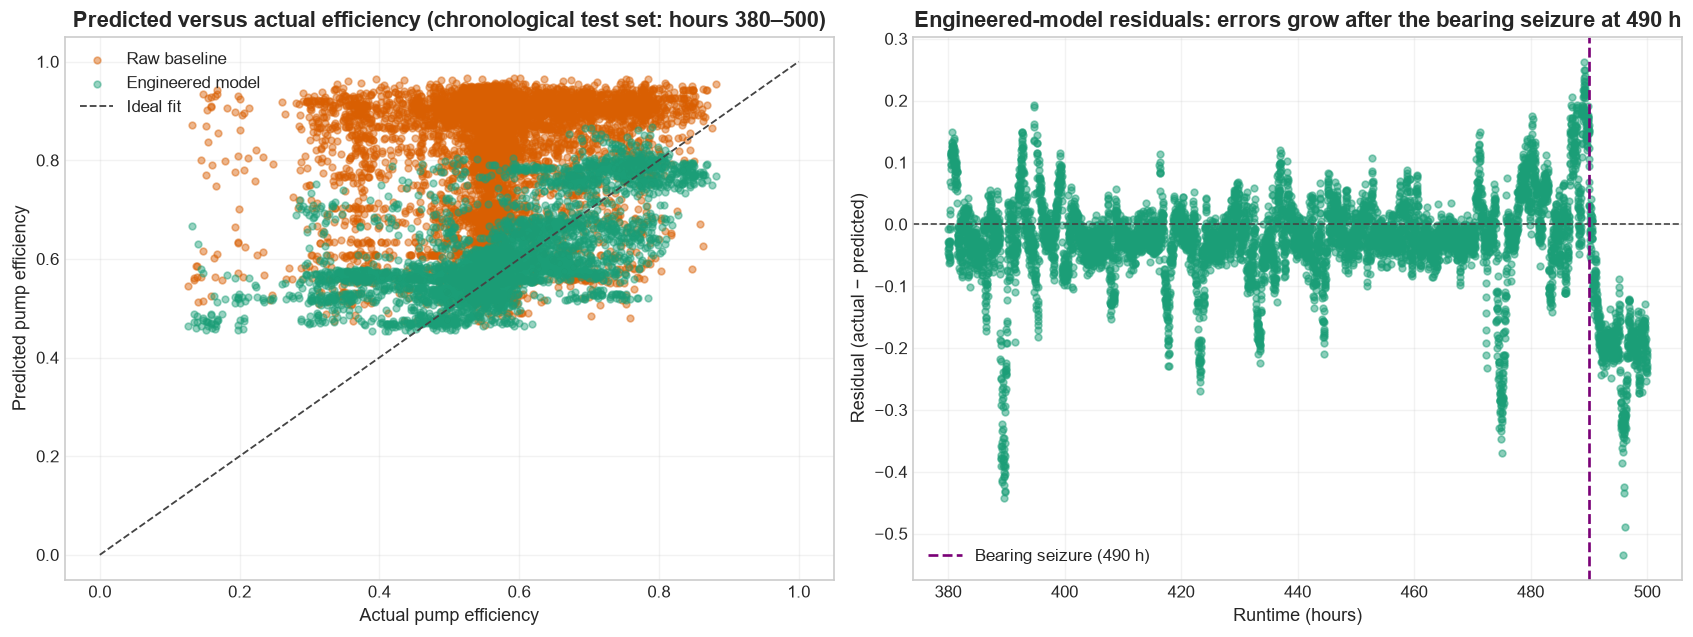

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.2), constrained_layout=True)

axes[0].scatter(test_df['pump_efficiency'], baseline_predictions, s=16, alpha=0.45, color='#d95f02', label='Raw baseline')
axes[0].scatter(test_df['pump_efficiency'], engineered_predictions, s=16, alpha=0.45, color='#1b9e77', label='Engineered model')
axes[0].plot([0, 1], [0, 1], color='#444444', linestyle='--', linewidth=1.1, label='Ideal fit')
axes[0].set_title('Predicted versus actual efficiency (chronological test set: hours 380–500)')
axes[0].set_xlabel('Actual pump efficiency')
axes[0].set_ylabel('Predicted pump efficiency')
axes[0].legend(loc='upper left')

residuals = test_df['pump_efficiency'].to_numpy() - engineered_predictions
axes[1].scatter(test_df['time_hours'], residuals, s=16, alpha=0.5, color='#1b9e77')
axes[1].axhline(0.0, color='#444444', linestyle='--', linewidth=1.0)
axes[1].axvline(x=SEIZURE_H, color='#7a0177', linestyle='--', linewidth=1.6, label=f'Bearing seizure ({SEIZURE_H:.0f} h)')
axes[1].set_title(f'Engineered-model residuals: errors grow after the bearing seizure at {SEIZURE_H:.0f} h')
axes[1].set_xlabel('Runtime (hours)')
axes[1].set_ylabel('Residual (actual − predicted)')
axes[1].legend(loc='lower left')

plt.show()

## Model Degradation and Confidence Breakdown

> **Physical situation:** The pump is now past its training window. The bearing is worn, cavitation is intermittent, and motor temperature is elevated. The model has never seen this operating state. We are asking it to predict in unfamiliar territory.

**Analytics anchor:** this is the Excel trendline extended past the edge of the data — the line keeps going, but your confidence should not.

The raw-feature model was trained only on data from hours 0-380. Here we ask it to predict across the full 500-hour lifespan and overlay the individual tree predictions to reveal disagreement.

Inside the training window the tree ensemble broadly agrees — the spread between individual trees is narrow. The moment the pump crosses into the failure regime (hour 360) and approaches the bearing seizure at 490 h, the trees diverge: each tree memorised different nominal operating patterns, and none of them saw this operating point before. That divergence is the model's uncertainty signal.

---

**Key insight:** the model does not know it is wrong. It keeps producing a number. The spread between trees is the only warning that the prediction should not be trusted. A system that only reports the mean prediction would silently deliver a confident wrong answer to the operator.

We also apply domain-knowledge hard limits (`enforce_physical_limits`) — when pressure drops severely below the local baseline (cavitation), efficiency *cannot* remain high regardless of what the model predicts.

In [12]:
chrono_train = working_df[working_df['suggested_split'] == 'train'].copy()
extrapolation_model = RandomForestRegressor(n_estimators=180, random_state=42, n_jobs=-1)
extrapolation_model.fit(chrono_train[raw_features], chrono_train['pump_efficiency'])

# Individual trees are fitted on bare arrays, so predict on arrays too
raw_matrix = working_df[raw_features].to_numpy()
all_tree_runs = np.stack([tree.predict(raw_matrix) for tree in extrapolation_model.estimators_], axis=0)
mean_pred = all_tree_runs.mean(axis=0)
std_pred = all_tree_runs.std(axis=0)

# Apply domain-knowledge hard limits: severe pressure deficit means efficiency cannot stay high
mean_pred_bounded = enforce_physical_limits(mean_pred, working_df)

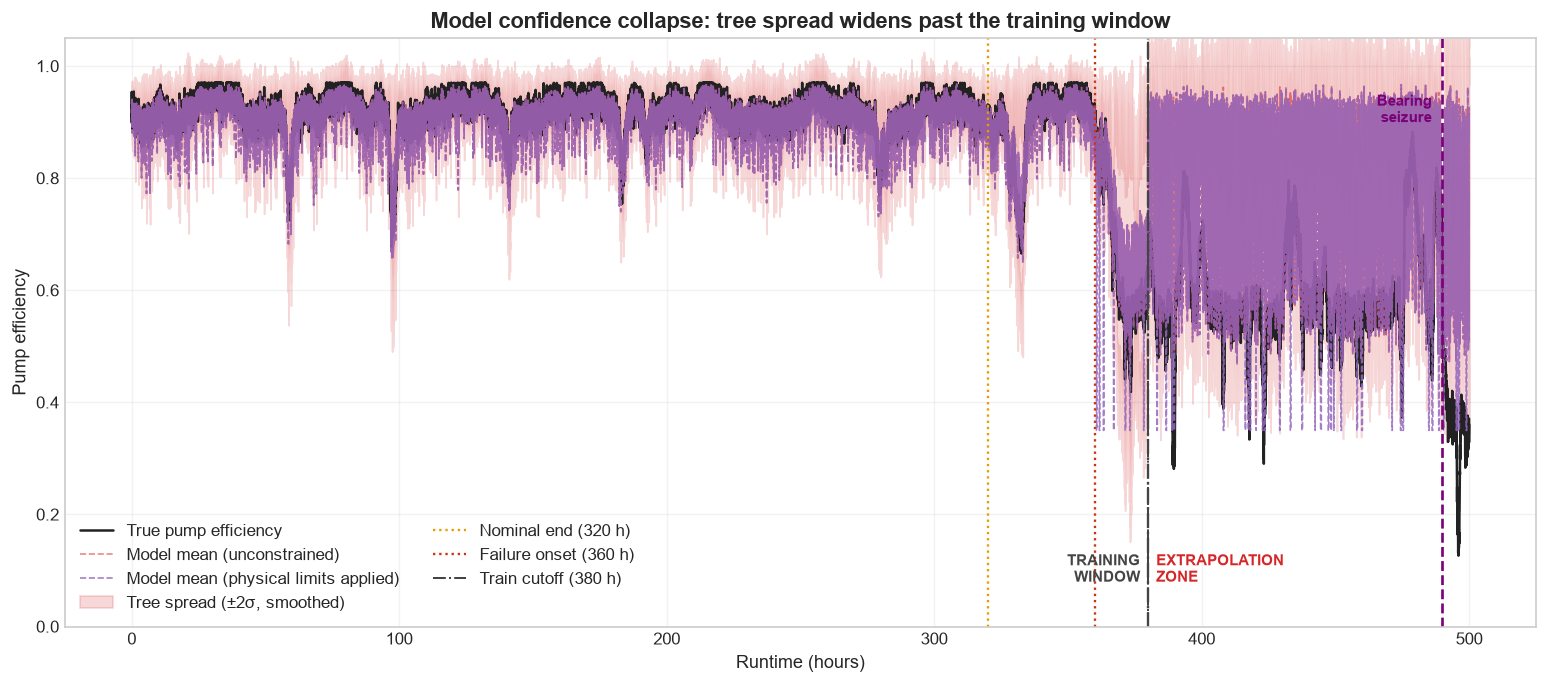

In [13]:
fig, ax = plt.subplots(figsize=(13, 5.8))
ax.plot(working_df['time_hours'], working_df['pump_efficiency'], color='#222222', linewidth=1.5, label='True pump efficiency')
ax.plot(working_df['time_hours'], mean_pred, color='#d62728', linestyle='--', linewidth=1.0, alpha=0.55, label='Model mean (unconstrained)')
ax.plot(working_df['time_hours'], mean_pred_bounded, color='#9467bd', linestyle='--', linewidth=1.0, alpha=0.85, label='Model mean (physical limits applied)')

# Smooth the per-timestep tree disagreement so the regime contrast is readable
std_smooth = pd.Series(std_pred).rolling(61, min_periods=1, center=True).mean().to_numpy()
ax.fill_between(working_df['time_hours'], mean_pred - 2 * std_smooth, mean_pred + 2 * std_smooth,
                color='#d62728', alpha=0.18, label='Tree spread (±2σ, smoothed)')

cutoff_hour = chrono_train['time_hours'].max()
ax.axvline(x=cutoff_hour, color='#444444', linestyle='-.', linewidth=1.4)
ax.text(cutoff_hour - 3, 0.08, 'TRAINING\nWINDOW', ha='right', color='#444444', weight='bold', fontsize=9)
ax.text(cutoff_hour + 3, 0.08, 'EXTRAPOLATION\nZONE', ha='left', color='#d62728', weight='bold', fontsize=9)

add_regime_lines(ax, legend=False)
ax.axvline(x=SEIZURE_H, color='#7a0177', linestyle='--', linewidth=1.6)
ax.text(SEIZURE_H - 4, 0.9, 'Bearing\nseizure', ha='right', color='#7a0177', fontsize=9, weight='bold')

ax.set_ylim(0.0, 1.05)
ax.set_xlabel('Runtime (hours)')
ax.set_ylabel('Pump efficiency')
ax.set_title('Model confidence collapse: tree spread widens past the training window')
ax.legend(loc='lower left', ncols=2)
plt.tight_layout()
plt.show()

## Gaussian Process Uncertainty in an Extreme Thermal Slice

A Random Forest expresses uncertainty through tree disagreement — a useful proxy, but it has no principled probabilistic interpretation. A **Gaussian Process (GPR)** models uncertainty directly: the posterior variance grows as the query point moves away from the training data.

**Analytics anchor:** a confidence interval that honestly widens where the data runs out.

We sweep motor temperature along a slice from the observed training range out into a regime the model has never seen (>80 °C). The shaded band shows ±2σ. Inside the training temperature range the band is narrow — the model has seen examples there and has learned the relationship. Outside it, the band widens steadily.

**Note:** This is a controlled ablation — vibration and pressure features are held at their median training values to isolate how uncertainty grows with temperature alone. It is not a real operating trajectory.

---

**What to notice:** the GPR mean prediction keeps extrapolating beyond the training boundary, but the widening uncertainty band correctly tells you that the model does not know what is happening at 85–95 °C. In a safety-critical system, that expanding band should trigger a human review, not an automated action based on the mean alone.

This is fundamentally different from the Random Forest: the GPR is calibrated to say "I don't know" in regions where it lacks data.

In [14]:
gp_train = chrono_train[['vibration_rms', 'vibration_trend', 'pressure_reserve', 'motor_temp', 'pump_efficiency']].sample(n=min(500, len(chrono_train)), random_state=42).sort_values('motor_temp').copy()
gpr_features_train = gp_train[['vibration_rms', 'vibration_trend', 'pressure_reserve', 'motor_temp']].copy()
gpr_scaler = StandardScaler()
gpr_train_scaled = gpr_scaler.fit_transform(gpr_features_train)

kernel = (
    ConstantKernel(1.0, (0.01, 100.0))
    * Matern(length_scale=np.ones(gpr_features_train.shape[1]),
             length_scale_bounds=(0.05, 5.0), nu=1.5)
)
gpr = GaussianProcessRegressor(
    kernel=kernel, alpha=0.02, normalize_y=True,
    n_restarts_optimizer=6, random_state=42
)
_ = gpr.fit(gpr_train_scaled, gp_train['pump_efficiency'])

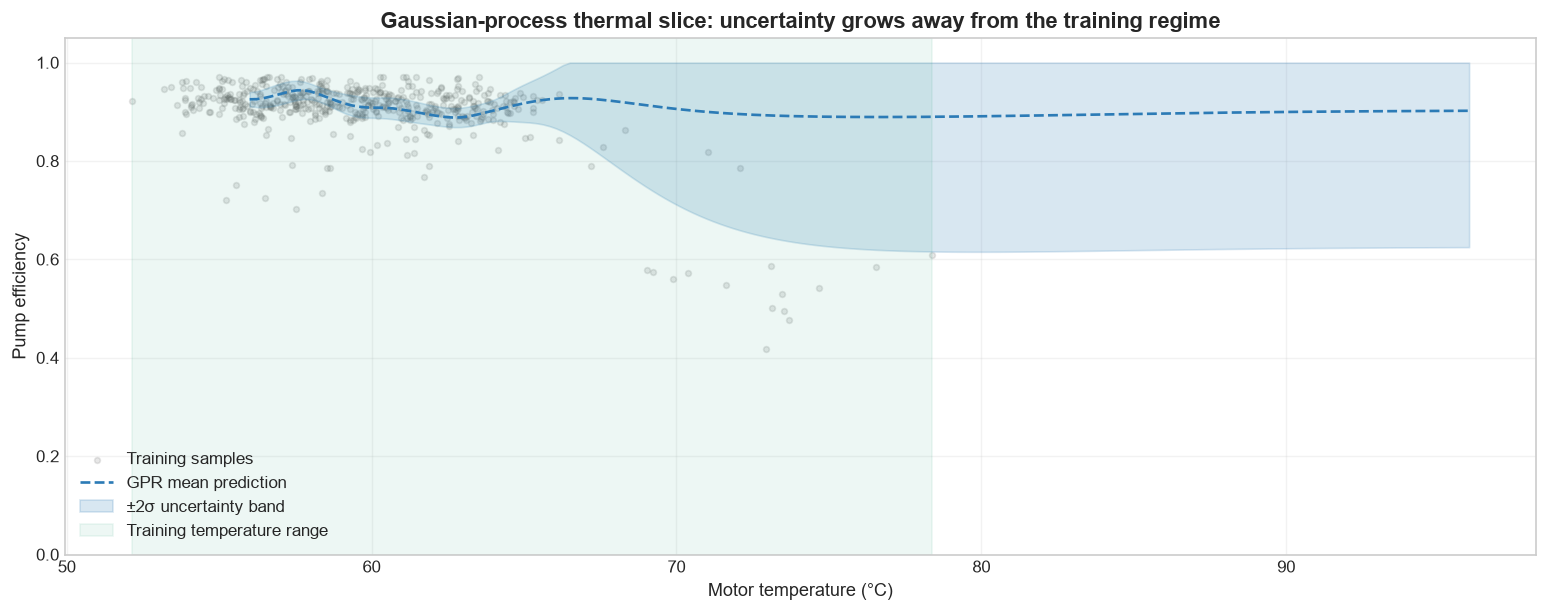

In [15]:
slice_anchor = gpr_features_train.median()
thermal_axis = np.linspace(56.0, 96.0, 180)
# Controlled ablation: every feature except motor_temp held at its training median
gpr_slice = pd.DataFrame({
    'vibration_rms': np.full(thermal_axis.size, slice_anchor['vibration_rms']),
    'vibration_trend': np.full(thermal_axis.size, slice_anchor['vibration_trend']),
    'pressure_reserve': np.full(thermal_axis.size, slice_anchor['pressure_reserve']),
    'motor_temp': thermal_axis,
})
gpr_mean, gpr_std = gpr.predict(gpr_scaler.transform(gpr_slice), return_std=True)
training_temp_range = (gp_train['motor_temp'].min(), gp_train['motor_temp'].max())

fig, ax = plt.subplots(figsize=(13, 5.2))
ax.scatter(gp_train['motor_temp'], gp_train['pump_efficiency'], s=12, alpha=0.14, color='#555555', label='Training samples')
ax.plot(thermal_axis, gpr_mean, color='#2c7bb6', linewidth=1.6, linestyle='--', label='GPR mean prediction')
ax.fill_between(thermal_axis, np.clip(gpr_mean - 2 * gpr_std, 0, 1), np.clip(gpr_mean + 2 * gpr_std, 0, 1), color='#2c7bb6', alpha=0.18, label='±2σ uncertainty band')
ax.axvspan(training_temp_range[0], training_temp_range[1], color='#1b9e77', alpha=0.08, label='Training temperature range')
ax.set_ylim(0.0, 1.05)
ax.set_xlabel('Motor temperature (°C)')
ax.set_ylabel('Pump efficiency')
ax.set_title('Gaussian-process thermal slice: uncertainty grows away from the training regime')
ax.legend(loc='lower left')
plt.tight_layout()
plt.show()

## Forensic Audit with SHAP

> **Physical situation:** The model has flagged a specific timestep as having critically low predicted efficiency. An operator is standing at the control panel. They need to know: *which component is failing, and what should I do right now?* A model that only outputs a number gives them nothing. SHAP translates the prediction into a ranked list of physical causes.

**Analytics anchor:** SHAP is a contribution breakdown — which line items drove the total, like a variance-to-budget waterfall in a finance pack.

SHAP (SHapley Additive exPlanations) uses Shapley values from cooperative game theory to fairly allocate the model's prediction to individual features. For each data point, every feature receives a credit or blame score that sums to the difference between that prediction and the model's average prediction.

The **summary plot** shows which features matter most across the entire test set, and in which direction — red means a high feature value pushed the prediction up, blue means it pushed it down.

The **force plot** below diagnoses a single specific prediction: the worst-efficiency data point in the test set.

---

**What to notice on the force plot:** the thermal, vibration and pressure state features all push the efficiency prediction strongly downward. This is not a statistical artefact — it directly corresponds to an overheating motor, an elevated bearing-load energy state and a significant pressure deficit. A maintenance engineer reading this output knows immediately: *check the cooling, inspect the bearing, and look for upstream cavitation.*

SHAP converts a black-box number into a maintenance action item.

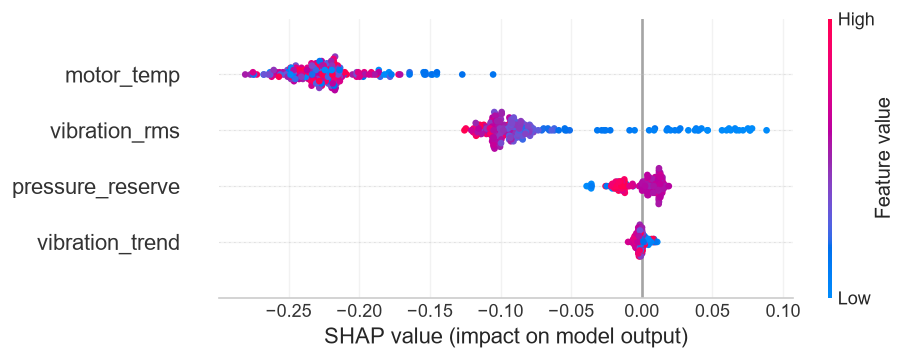

Diagnosing worst test-set prediction:
  Time: 496.0 h  |  Actual efficiency: 0.126  |  Predicted: 0.464


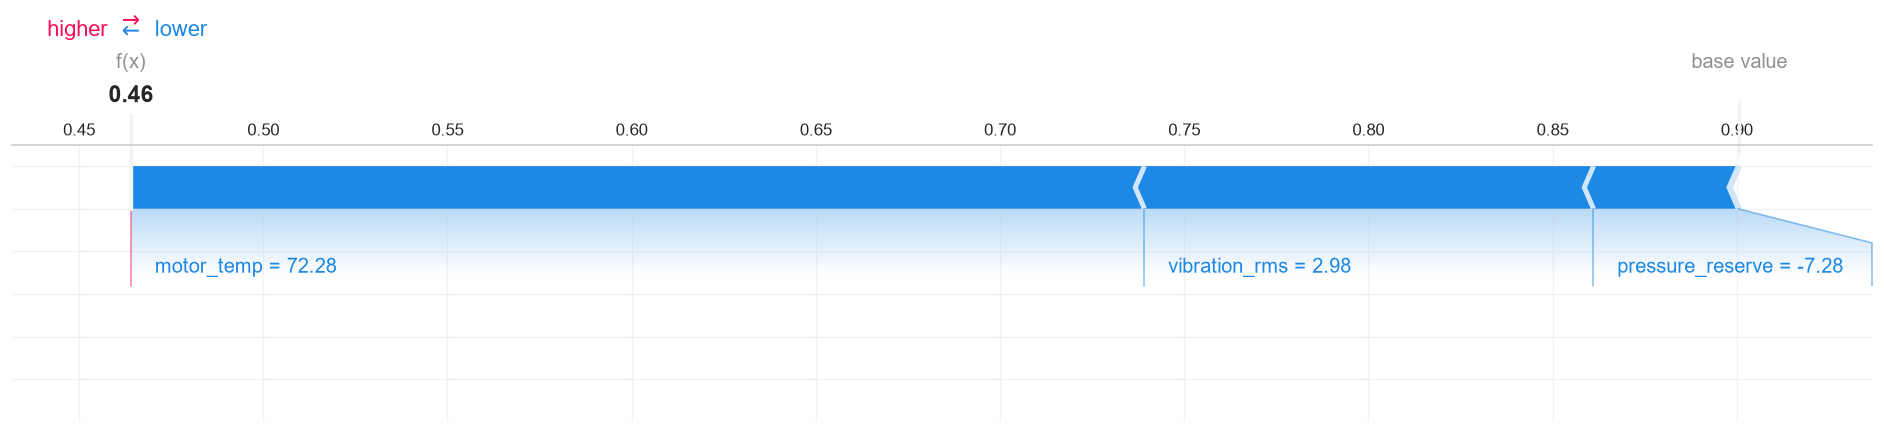

In [16]:
shap_sample = test_df[engineered_features].sample(n=min(240, len(test_df)), random_state=42)
shap_explainer = shap.TreeExplainer(engineered_model)
shap_values = shap_explainer.shap_values(shap_sample)

shap.summary_plot(shap_values, shap_sample, show=True)

anomalous_point = test_df.sort_values('pump_efficiency').head(1)
anomalous_row = anomalous_point[engineered_features]
print(f"Diagnosing worst test-set prediction:")
print(f"  Time: {anomalous_point['time_hours'].values[0]:.1f} h  |  "
      f"Actual efficiency: {anomalous_point['pump_efficiency'].values[0]:.3f}  |  "
      f"Predicted: {engineered_model.predict(anomalous_row)[0]:.3f}")
shap_force = shap_explainer.shap_values(anomalous_row)
shap.force_plot(shap_explainer.expected_value, shap_force[0], anomalous_row.round(2).iloc[0], matplotlib=True, show=True)

### From SHAP values to a maintenance action

The force plot above shows *why* the model predicted that specific low-efficiency reading. Reading it as an engineer, in order of SHAP impact:

| Feature with high SHAP impact | Physical interpretation | Maintenance action |
|---|---|---|
| `motor_temp` (elevated, pushes down) | Thermal accumulation; possible winding degradation or inadequate cooling | Inspect cooling fins and check motor winding resistance |
| `vibration_rms` (high, pushes down) | Elevated bearing-load energy; mechanical wear accumulating | Inspect and grease or replace bearings |
| `pressure_reserve` (negative, pushes down) | Pressure repeatedly dropping below local baseline; intermittent cavitation | Check upstream valve and impeller for cavitation damage |
| `vibration_trend` (rising) | Energy envelope is increasing over time; fault is actively progressing | Schedule shutdown before next maintenance window |

This is what explainability means in practice. Not "the model gives a confidence score" — but "the model tells you which physical system is failing and what to do about it."

A prediction without an explanation is a number. A prediction *with* a SHAP breakdown is a maintenance report.

## Summary

| Stage | What we showed | The lesson |
|---|---|---|
| Raw signal | Noisy, carrier-dominated time series | Sensor data is rarely usable as-is |
| Cleaning | Dropout fill, SG filter, drift correction | Domain knowledge unlocks the signal before any ML starts |
| Feature engineering | RMS, trend, pressure reserve, temp | Physics-aware features change R² more than algorithm choice does |
| Split strategy | Shuffled vs chronological | The evaluation strategy determines what the score *means* |
| Model degradation | RF tree spread beyond the training window | Models do not know they are wrong — spread is the only warning |
| Uncertainty (GPR) | Posterior variance grows outside training data | A prediction without a confidence bound is dangerous in safety-critical systems |
| SHAP | Feature attribution on the worst-case prediction | Explainability converts a model output into a maintenance action |

The model is a tool. Understanding its limits — and communicating them honestly — is the engineering skill.